# Introducción

**Nombre:** VISIT_OCCURRENCE
**Descripción:** Esta tabla contiene eventos en los que las personas interactúan con el sistema sanitario durante un periodo de tiempo determinado. A menudo, estos eventos también reciben el nombre de «encuentros». Las visitas se definen según un conjunto de circunstancias en las que tienen lugar, tales como: (i) si el paciente acude a una institución sanitaria, si ocurre a la inversa o si la interacción es remota; (ii) si interviene personal médico cualificado —y de qué tipo— para prestar el servicio durante la visita; y (iii) si la visita es de carácter puntual o si, por el contrario, se prolonga durante un periodo más largo que conlleva una estancia en cama.

**Significado de cada columna:** 

- visit_occurrence_id: Identificador único de cada visita o encuentro clínico del paciente.
- person_id: Identificador del paciente asociado a la visita.
- visit_concept_id: Identificador estandarizado del tipo de visita (urgencias, hospitalización, consulta, etc.).
- visit_start_datetime: Fecha y hora de inicio de la visita hospitalaria.
- visit_end_datetime: Fecha y hora de finalización de la visita hospitalaria.
- visit_type_concept_id: Identificador que describe el origen o tipo de registro de la visita.
- provider_id: Identificador del profesional de salud asociado a la visita.

# 2. Carga y reconocimiento de los datos

In [1]:
!pip install pandas


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [12]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
visit_ocurrence = pd.read_csv(
    "../data/visit_occurrence_202611061448.csv")

In [6]:
#Dimensiones de la tabla
rows, column = (visit_ocurrence.shape)
print(f"rows: {rows} \ncolumn {column}")

total_visit = len(visit_ocurrence)
print(f"total_visit: {total_visit}")

rows: 1706001 
column 6
total_visit: 1706001


In [7]:
#Valores nulos
null_amount = visit_ocurrence.isnull().sum()
null_porcent = (null_amount/total_visit)*100

summary_null = pd.DataFrame({
    'Missing values': null_amount,
    'Porcent (%)': null_porcent
})

print(summary_null.sort_values(by='Missing values', ascending=False))

                      Missing values  Porcent (%)
visit_occurrence_id                0          0.0
person_id                          0          0.0
visit_concept_id                   0          0.0
visit_start_datetime               0          0.0
visit_end_datetime                 0          0.0
provider_id                        0          0.0


In [5]:
#Duplicate records
duplicate_records = visit_ocurrence.duplicated().sum
columnas_afectadas = list(visit_ocurrence.columns)

summary_duplicated = {
    "total_duplicated": duplicate_records,
    "columns_in": columnas_afectadas,
}

#print(summary_duplicated)

duplicate_id = visit_ocurrence["visit_occurrence_id"].duplicated().sum
print(duplicate_id)

<bound method Series.sum of 0          False
1          False
2          False
3          False
4          False
           ...  
1705996    False
1705997    False
1705998    False
1705999    False
1706000    False
Name: visit_occurrence_id, Length: 1706001, dtype: bool>


In [4]:
#Invalid Start date
visit_ocurrence['visit_start_datetime'] = pd.to_datetime(
    visit_ocurrence['visit_start_datetime'], errors='coerce'
)

total_invalid_start = visit_ocurrence['visit_start_datetime'].isna().sum()
print(f"Null dates: {total_invalid_start}")

#Invalid End date
visit_ocurrence['visit_end_datetime'] = pd.to_datetime(visit_ocurrence['visit_end_datetime'], errors='coerce')
total_invalid_end = visit_ocurrence['visit_end_datetime'].isna().sum()
print(f"Null dates: {total_invalid_end}")


#Inverted dates 
fechas_invertidas = visit_ocurrence['visit_end_datetime'] < visit_ocurrence['visit_start_datetime']

print(f"Records where the end date is earlier than the start date: {fechas_invertidas.sum()}")
print(visit_ocurrence[fechas_invertidas][['visit_start_datetime', 'visit_end_datetime']])

Null dates: 0
Null dates: 0
Records where the end date is earlier than the start date: 0
Empty DataFrame
Columns: [visit_start_datetime, visit_end_datetime]
Index: []


In [ ]:
#Duration 
# Calcule duration of visit
duracion = visit_ocurrence['visit_end_datetime'] - visit_ocurrence['visit_start_datetime']

# Average
print(duracion.dt.total_seconds() / 60)

#Here we cannot calculus the duration because visit_end_datetime and visit_start_datetime is the same.

0          0.0
1          0.0
2          0.0
3          0.0
4          0.0
          ... 
1705996    0.0
1705997    0.0
1705998    0.0
1705999    0.0
1706000    0.0
Length: 1706001, dtype: float64


In [ ]:
#Displays the first 5 rows, comparing the start, end, and calculated duration.
print(visit_ocurrence[['visit_start_datetime', 'visit_end_datetime']].head())

  visit_start_datetime  visit_end_datetime
0  2023-01-29 14:18:58 2023-01-29 14:18:58
1  2023-01-29 14:19:25 2023-01-29 14:19:25
2  2023-01-29 14:21:42 2023-01-29 14:21:42
3  2023-01-29 14:25:11 2023-01-29 14:25:11
4  2023-01-29 14:26:37 2023-01-29 14:26:37


In [4]:
#Minimun and maximun date
min_date = visit_ocurrence["visit_start_datetime"].min()
max_date = visit_ocurrence["visit_start_datetime"].max()

print(f"Minimun: {min_date}\nMaximun: {max_date}")


Minimun: 2023-01-01 00:21:55.000
Maximun: 2026-08-13 15:20:00.000


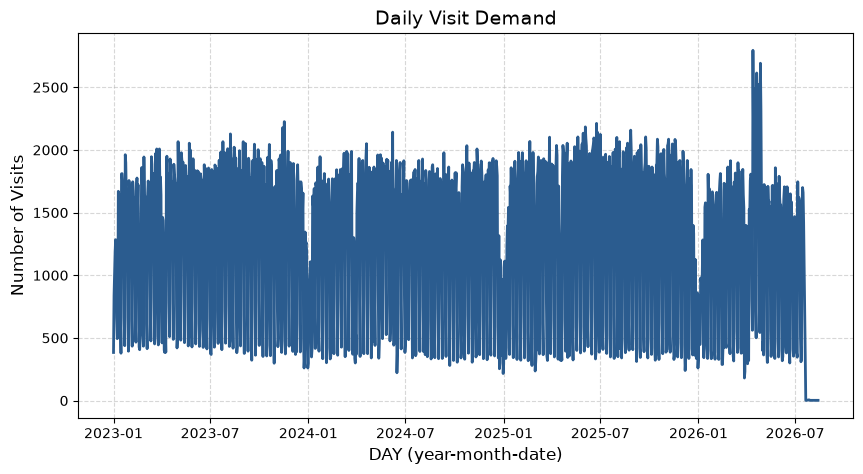

Average: 1310.2926267281107
Minimun: 2 
Maximun: 2795


In [34]:
#Daily demand
visit_ocurrence["visit_start_datetime"] = pd.to_datetime(visit_ocurrence["visit_start_datetime"])
daily_demand = visit_ocurrence.groupby(visit_ocurrence["visit_start_datetime"].dt.date).size()
#print(daily_demand)

plt.figure(figsize=(10, 5))
daily_demand.plot(kind='line', color='#2b5c8f', linewidth=2)

plt.title('Daily Visit Demand', fontsize=14)
plt.xlabel('DAY (year-month-date)', fontsize=12)
plt.ylabel('Number of Visits', fontsize=12)

plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

#Daily demand average, minimun and maximun
average_daily = daily_demand.mean()
minimun_daily = daily_demand.min()
maximun_daily=daily_demand.max()
print(f"Average: {average_daily}")
print(f"Minimun: {minimun_daily} \nMaximun: {maximun_daily}")

C:\Users\sierr\AppData\Local\Temp\ipykernel_13252\3975115858.py:3: Pandas4Warning: Series.dt.weekday is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  day_week_demand = visit_ocurrence.groupby(visit_ocurrence["visit_start_datetime"].dt.weekday).size()


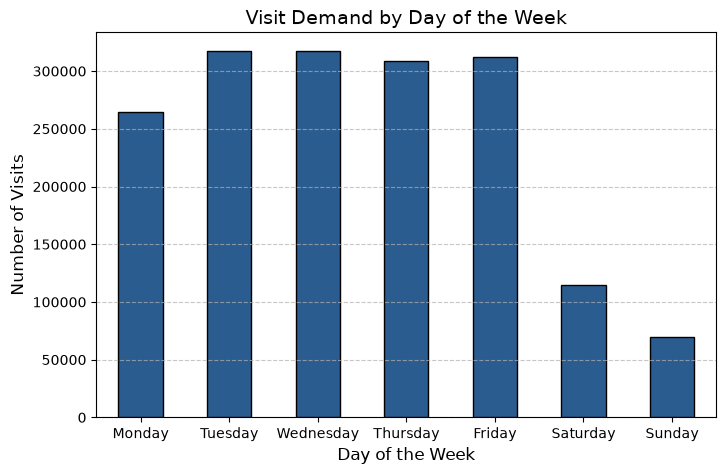

The day with most registers is Wednesday with 317667 visit.
The day with the least registers is Sunday with 69490 visits.


In [33]:
#Demand by day of the week
visit_ocurrence["visit_start_datetime"] = pd.to_datetime(visit_ocurrence["visit_start_datetime"])
day_week_demand = visit_ocurrence.groupby(visit_ocurrence["visit_start_datetime"].dt.weekday).size()
#print(day_week_demand)

plt.figure(figsize=(8, 5))
day_week_demand.plot(kind='bar', color='#2b5c8f', edgecolor='black')

plt.title('Visit Demand by Day of the Week', fontsize=14)
plt.xlabel('Day of the Week', fontsize=12)
plt.ylabel('Number of Visits', fontsize=12)


plt.xticks(
    ticks=range(7), 
    labels=['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday'], 
    rotation=0
)

plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

days_names = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']

max_day_index = day_week_demand.idxmax()
min_day_index = day_week_demand.idxmin()

max_day_name = days_names[max_day_index]
max_visits = day_week_demand[max_day_index]

min_day_name = days_names[min_day_index]
min_visits = day_week_demand[min_day_index]

# Mostrar resultados
print(f"The day with most registers is {max_day_name} with {max_visits} visit.")
print(f"The day with the least registers is {min_day_name} with {min_visits} visits.")


visit_start_datetime
0      11736
1       7769
2       6311
3       5588
4       5407
5       9392
6      27039
7     108262
8     187996
9     203266
10    176637
11    146978
12     78003
13    137110
14    162697
15    142885
16    102753
17     45985
18     37781
19     23208
20     23595
21     21555
22     19175
23     14873
dtype: int64


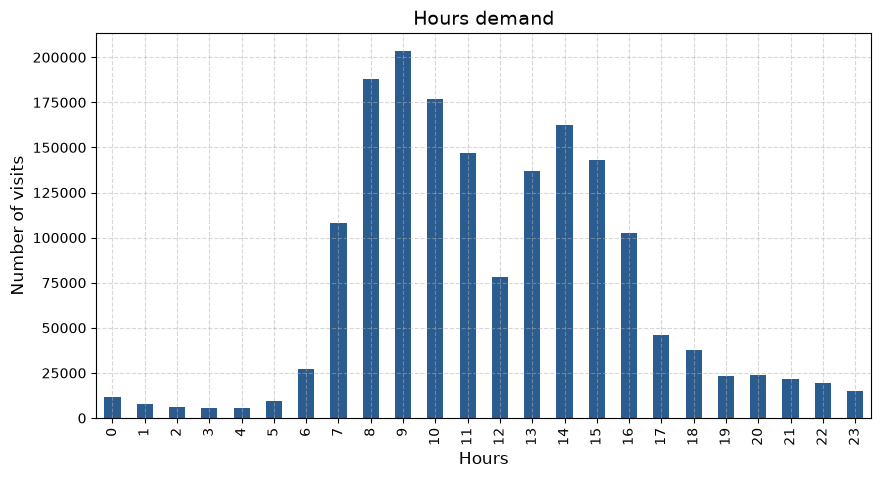

In [ ]:
#Demand by hours
visit_ocurrence["visit_start_datetime"] = pd.to_datetime(visit_ocurrence["visit_start_datetime"])
hours_demand = visit_ocurrence.groupby(visit_ocurrence["visit_start_datetime"].dt.hour).size()
#print(hours_demand)

plt.figure(figsize=(10, 5))
hours_demand.plot(kind='bar', color='#2b5c8f', linewidth=2)


plt.title('Hours demand', fontsize=14)
plt.xlabel('Hours', fontsize=12)
plt.ylabel('Number of visits', fontsize=12)

plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

visit_start_datetime
1     147389
2     143721
3     159185
4     170102
5     169231
6     154086
7     151306
8     127595
9     127991
10    127948
11    121268
12    106179
dtype: int64


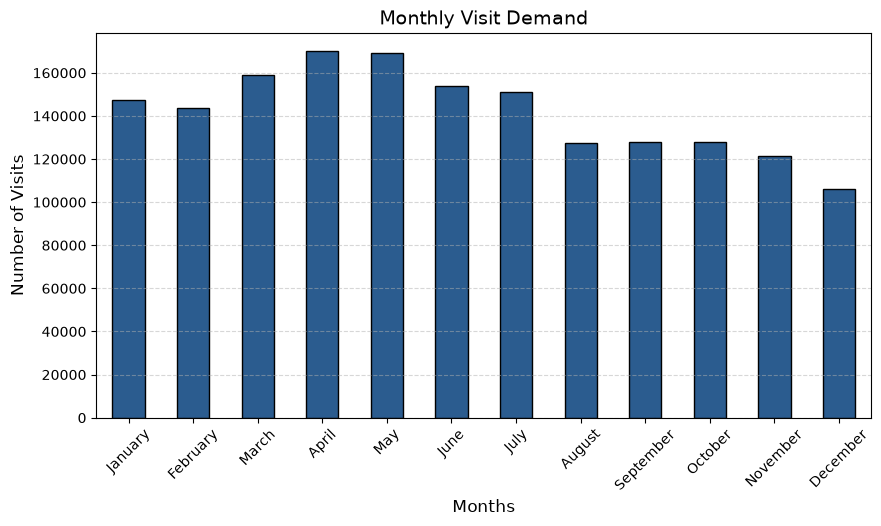

In [ ]:
#Demand by moth
visit_ocurrence["visit_start_datetime"] = pd.to_datetime(visit_ocurrence["visit_start_datetime"])
month_demand = visit_ocurrence.groupby(visit_ocurrence["visit_start_datetime"].dt.month).size()
print(month_demand)

plt.figure(figsize=(10, 5))
month_demand.plot(kind='bar', color='#2b5c8f', edgecolor='black')


plt.title('Monthly Visit Demand', fontsize=14)
plt.xlabel('Months', fontsize=12)
plt.ylabel('Number of Visits', fontsize=12)

plt.xticks(
    ticks=range(len(month_demand)),
    labels=[
        "January", "February", "March", "April", "May", "June", 
        "July", "August", "September", "October", "November", "December"
    ][:len(month_demand)], 
    rotation=45
)

plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()
